In [ ]:
import numpy as np
import pandas as pd
from sklearn.linear_model import SGDRegressor

In [2]:
# 读取数据
df = pd.read_csv('data/used_cars.csv', sep=',', header=0)
df.head()

,SaleID,name,model,regionCode,brand,bodyType,fuelType,gearbox,power,kilometer,notRepairedDamage,days,v_0,v_1,price
0,12023,444,40.0,2263,1,2.0,1.0,1.0,140,15.0,0.0,3400,46.649986,0.053581,5200
1,29641,10607,0.0,4791,0,1.0,0.0,0.0,75,15.0,0.0,7308,42.250023,0.035016,888
2,58875,173321,17.0,3060,10,0.0,0.0,0.0,0,15.0,0.0,6908,43.660473,0.024292,750
3,115050,58480,19.0,1820,19,2.0,0.0,0.0,179,15.0,0.0,6724,45.549189,0.039061,3000
4,39236,34799,0.0,3304,0,3.0,1.0,0.0,105,15.0,0.0,4026,45.290226,0.055210,3600


In [3]:
columns = df.columns[4:]
df = df[columns]
df.head()

,brand,bodyType,fuelType,gearbox,power,kilometer,notRepairedDamage,days,v_0,v_1,price
0,1,2.0,1.0,1.0,140,15.0,0.0,3400,46.649986,0.053581,5200
1,0,1.0,0.0,0.0,75,15.0,0.0,7308,42.250023,0.035016,888
2,10,0.0,0.0,0.0,0,15.0,0.0,6908,43.660473,0.024292,750
3,19,2.0,0.0,0.0,179,15.0,0.0,6724,45.549189,0.039061,3000
4,0,3.0,1.0,0.0,105,15.0,0.0,4026,45.290226,0.055210,3600


In [4]:
df = (df - df.min()) / (df.max() - df.min())          # min-max归一化
df.head()

,brand,bodyType,fuelType,gearbox,power,kilometer,notRepairedDamage,days,v_0,v_1,price
0,0.025641,0.285714,0.166667,1.0,0.233333,1.0,0.0,0.362281,0.662581,0.363489,0.057951
1,0.000000,0.142857,0.000000,0.0,0.125000,1.0,0.0,0.790789,0.358791,0.237542,0.009477
2,0.256410,0.000000,0.000000,0.0,0.000000,1.0,0.0,0.746930,0.456174,0.164792,0.007925
3,0.487179,0.285714,0.000000,0.0,0.298333,1.0,0.0,0.726754,0.586578,0.264984,0.033219
4,0.000000,0.428571,0.166667,0.0,0.175000,1.0,0.0,0.430921,0.568698,0.374536,0.039964


In [5]:
# 划分训练集和测试集
train_data = df.sample(frac=0.8, replace=False)
test_data = df.drop(train_data.index)

# x_train = train_data.iloc[:, :-1].values
# y_train = train_data.iloc[:, -1].values
x_train = train_data.values[:, :-1]
y_train = train_data.values[:, -1]

x_test = test_data.values[:, :-1]
y_test = test_data.values[:, -1]

In [6]:
# 模型的构建与训练
model = SGDRegressor(max_iter=1000, learning_rate='adaptive', eta0=0.01, loss='huber')
model.fit(x_train, y_train)

,loss,'huber'
,penalty,'l2'
,alpha,0.0001
,l1_ratio,0.15
,fit_intercept,True
,max_iter,1000
,tol,0.001
,shuffle,True
,verbose,0
,epsilon,0.1
,random_state,None


In [7]:
model.coef_, model.intercept_

(array([-0.01806395,  0.01116805,  0.0016941 ,  0.01020248,  0.14159547,
        -0.05434915, -0.00256436, -0.04305296,  0.18012041,  0.08295809]),
 array([-0.0262006]))

In [8]:
# 在测试集上预测
y_pred = model.predict(x_test)
mse = np.mean((y_pred - y_test)**2)
mse

np.float64(0.001967697256069159)

In [9]:
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Microsoft Yahei'

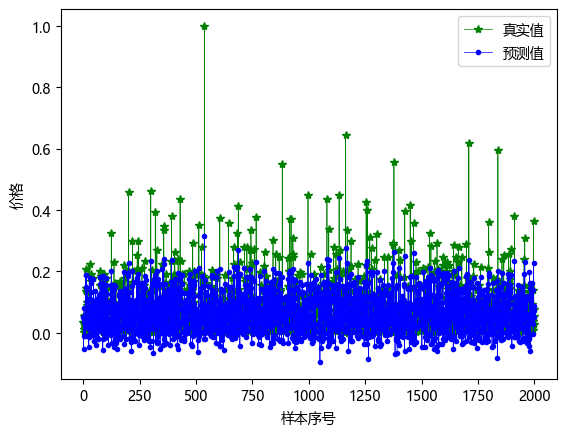

In [18]:
plt.Figure(figsize=(12,5))
ax1 = plt.subplot(111)
x = range(len(y_test))
plt.plot(x,y_test,'g',label='真实值',marker='*',linewidth=0.5)
plt.plot(x,y_pred,'b',label='预测值',marker='.',linewidth=0.5)
ax1.set_xlabel('样本序号')
ax1.set_ylabel('价格')
plt.legend(loc='upper right')
plt.show()